In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from amplpy import AMPL, ampl_notebook

In [5]:
ampl = ampl_notebook(modules=["highs"])

In [6]:
df_current_plan = pd.read_csv(
    "https://raw.githubusercontent.com/Gurobi/modeling-examples/master/aviation_planning/data/flight_rotations_2006-07-01.csv"
)

df_starting_positions = pd.read_csv(
    "https://raw.githubusercontent.com/Gurobi/modeling-examples/master/aviation_planning/data/starting_positions.csv"
)

df_ending_positions = pd.read_csv(
    "https://raw.githubusercontent.com/Gurobi/modeling-examples/master/aviation_planning/data/ending_positions.csv"
)

df_itineraries = pd.read_csv(
    "https://raw.githubusercontent.com/Gurobi/modeling-examples/master/aviation_planning/data/flight_iterinaries.csv"
)

print("Current plan:", df_current_plan.shape)
print("Starting positions:", df_starting_positions.shape)
print("Ending positions:", df_ending_positions.shape)
print("Itineraries:", df_itineraries.shape)

Current plan: (608, 8)
Starting positions: (85, 2)
Ending positions: (85, 2)
Itineraries: (1930, 3)


In [7]:
df_current_plan["start_time"] = pd.to_datetime(df_current_plan["start_time"], format="%H:%M")
df_current_plan["end_time"] = pd.to_datetime(df_current_plan["end_time"], format="%H:%M")
df_current_plan["duration"] = pd.to_datetime(df_current_plan["duration"], format="%H:%M")

df_current_plan.head()

,flight,date,aircraft,ori,des,start_time,end_time,duration
0,1,7/1/06,TranspCom#1,CDG,ORY,1900-01-01 00:00:00,1900-01-01 00:30:00,1900-01-01 00:30:00
1,73,7/1/06,TranspCom#3,ORY,CDG,1900-01-01 00:00:00,1900-01-01 00:30:00,1900-01-01 00:30:00
2,2,7/1/06,TranspCom#2,CDG,ORY,1900-01-01 00:20:00,1900-01-01 00:50:00,1900-01-01 00:30:00
3,74,7/1/06,TranspCom#4,ORY,CDG,1900-01-01 00:20:00,1900-01-01 00:50:00,1900-01-01 00:30:00
4,75,7/1/06,TranspCom#1,ORY,CDG,1900-01-01 00:40:00,1900-01-01 01:10:00,1900-01-01 00:30:00


In [8]:
n_airports = 4

all_airports_series = pd.concat([df_current_plan["ori"], df_current_plan["des"]])
top_airports = all_airports_series.value_counts().head(n_airports).index.tolist()

df_current_plan = df_current_plan[
    df_current_plan["ori"].isin(top_airports) & df_current_plan["des"].isin(top_airports)
].copy()

print("Top airports selected:", top_airports)
print("Reduced dataset shape:", df_current_plan.shape)
df_current_plan.head()

Top airports selected: ['ORY', 'CDG', 'LYS', 'NCE']
Reduced dataset shape: (222, 8)


,flight,date,aircraft,ori,des,start_time,end_time,duration
0,1,7/1/06,TranspCom#1,CDG,ORY,1900-01-01 00:00:00,1900-01-01 00:30:00,1900-01-01 00:30:00
1,73,7/1/06,TranspCom#3,ORY,CDG,1900-01-01 00:00:00,1900-01-01 00:30:00,1900-01-01 00:30:00
2,2,7/1/06,TranspCom#2,CDG,ORY,1900-01-01 00:20:00,1900-01-01 00:50:00,1900-01-01 00:30:00
3,74,7/1/06,TranspCom#4,ORY,CDG,1900-01-01 00:20:00,1900-01-01 00:50:00,1900-01-01 00:30:00
4,75,7/1/06,TranspCom#1,ORY,CDG,1900-01-01 00:40:00,1900-01-01 01:10:00,1900-01-01 00:30:00


In [9]:
flights = sorted(df_current_plan["flight"].unique().tolist())
aircrafts = sorted(df_current_plan["aircraft"].unique().tolist())
airports = sorted(set(df_current_plan["ori"]).union(set(df_current_plan["des"])))

flight_origin = df_current_plan.set_index("flight")["ori"].to_dict()
flight_dest = df_current_plan.set_index("flight")["des"].to_dict()
flight_start_time = df_current_plan.set_index("flight")["start_time"].to_dict()
flight_end_time = df_current_plan.set_index("flight")["end_time"].to_dict()

aircraft_start = df_starting_positions.set_index("aircraft")["airport"].to_dict()
aircraft_end = df_ending_positions.set_index("aircraft")["airport"].to_dict()

print("Flights:", len(flights))
print("Aircraft:", len(aircrafts))
print("Airports:", len(airports))
print("Airport list:", airports)

Flights: 222
Aircraft: 21
Airports: 4
Airport list: ['CDG', 'LYS', 'NCE', 'ORY']


In [10]:
df_itineraries["total_cost"] = df_itineraries["cost"] * df_itineraries["n_pass"]

flight_revenue_all = df_itineraries.groupby("flight")["total_cost"].sum().to_dict()
flight_passengers_all = df_itineraries.groupby("flight")["n_pass"].sum().to_dict()

flight_revenue = {f: float(flight_revenue_all[f]) for f in flights if f in flight_revenue_all}
flight_passengers = {f: float(flight_passengers_all[f]) for f in flights if f in flight_passengers_all}

flights = sorted(flight_revenue.keys())

df_current_plan = df_current_plan[df_current_plan["flight"].isin(flights)].copy()

flight_origin = df_current_plan.set_index("flight")["ori"].to_dict()
flight_dest = df_current_plan.set_index("flight")["des"].to_dict()
flight_start_time = df_current_plan.set_index("flight")["start_time"].to_dict()
flight_end_time = df_current_plan.set_index("flight")["end_time"].to_dict()

print("Flights with revenue data:", len(flights))

Flights with revenue data: 77


In [11]:
aircraft_flights = df_current_plan.groupby("aircraft")["flight"].apply(list).to_dict()

for a in aircrafts:
    if a not in aircraft_flights:
        aircraft_flights[a] = []

for a in aircrafts:
    aircraft_flights[a] = sorted(aircraft_flights[a])

aircraft_flights

{'A318#4': [3064, 3069, 3074, 3077, 3082, 3085, 3092, 3095],
 'A318#5': [3065, 3070, 3075, 3080, 3083, 3090, 3093],
 'A318#7': [4506, 4515],
 'A318#8': [3068, 3073, 3081, 3088, 3102, 3103],
 'A319#11': [3086, 3097, 3107, 3108],
 'A319#13': [3067],
 'A319#18': [4503, 4509, 4510, 4513, 4514, 4516],
 'A319#5': [3111, 3112],
 'A319#9': [3084, 3091, 3099],
 'A320#11': [4269, 4270, 4271, 4276],
 'A320#14': [4504, 4507, 4508, 4511],
 'A320#22': [4575, 4576, 4577, 4578],
 'A320#24': [3106, 4565, 4566, 4569, 4574],
 'A321#2': [4264, 4265, 4268, 4272, 4273, 4274, 4275, 4279],
 'A321#4': [4563, 4564, 4567, 4568, 4571, 4572],
 'CRJ700#3': [3063, 3076],
 'ERJ145#5': [4693, 4694, 4695, 4696, 4700],
 'TranspCom#1': [],
 'TranspCom#2': [],
 'TranspCom#3': [],
 'TranspCom#4': []}

In [12]:
flight_arcs_for_each_aircraft = {}
deltaplus = {}
deltaminus = {}
nodes_by_aircraft = {}

for a in aircrafts:
    source = f"source_{a}"
    sink = f"sink_{a}"

    real_flights = list(aircraft_flights[a])
    nodes = real_flights + [source, sink]
    nodes_by_aircraft[a] = nodes

    arcs = []
    deltaplus[a] = {n: [] for n in nodes}
    deltaminus[a] = {n: [] for n in nodes}

    # source -> real flight
    for f in real_flights:
        if aircraft_start.get(a) == flight_origin[f]:
            arcs.append((source, f))
            deltaplus[a][source].append(f)
            deltaminus[a][f].append(source)

    # real flight -> sink
    for f in real_flights:
        if flight_dest[f] == aircraft_end.get(a):
            arcs.append((f, sink))
            deltaplus[a][f].append(sink)
            deltaminus[a][sink].append(f)

    # real flight -> real flight
    for f1 in real_flights:
        for f2 in real_flights:
            if f1 == f2:
                continue
            if flight_dest[f1] == flight_origin[f2] and flight_end_time[f1] < flight_start_time[f2]:
                arcs.append((f1, f2))
                deltaplus[a][f1].append(f2)
                deltaminus[a][f2].append(f1)

    # allow unused aircraft
    arcs.append((source, sink))
    deltaplus[a][source].append(sink)
    deltaminus[a][sink].append(source)

    flight_arcs_for_each_aircraft[a] = arcs

for a in aircrafts:
    print(a, "-> flights:", len(aircraft_flights[a]), "| arcs:", len(flight_arcs_for_each_aircraft[a]))

A318#4 -> flights: 8 | arcs: 25
A318#5 -> flights: 7 | arcs: 21
A318#7 -> flights: 2 | arcs: 2
A318#8 -> flights: 6 | arcs: 16
A319#11 -> flights: 4 | arcs: 9
A319#13 -> flights: 1 | arcs: 2
A319#18 -> flights: 6 | arcs: 16
A319#5 -> flights: 2 | arcs: 4
A319#9 -> flights: 3 | arcs: 5
A320#11 -> flights: 4 | arcs: 5
A320#14 -> flights: 4 | arcs: 5
A320#22 -> flights: 4 | arcs: 9
A320#24 -> flights: 5 | arcs: 10
A321#2 -> flights: 8 | arcs: 25
A321#4 -> flights: 6 | arcs: 14
CRJ700#3 -> flights: 2 | arcs: 4
ERJ145#5 -> flights: 5 | arcs: 12
TranspCom#1 -> flights: 0 | arcs: 1
TranspCom#2 -> flights: 0 | arcs: 1
TranspCom#3 -> flights: 0 | arcs: 1
TranspCom#4 -> flights: 0 | arcs: 1


In [13]:
Carr = {}
Cdep = {}

for i in airports:
    Carr[i] = sum(1 for f in flights if flight_dest[f] == i)
    Cdep[i] = sum(1 for f in flights if flight_origin[f] == i)

print("Arrival capacities:", Carr)
print("Departure capacities:", Cdep)

Arrival capacities: {'CDG': 12, 'LYS': 15, 'NCE': 27, 'ORY': 23}
Departure capacities: {'CDG': 13, 'LYS': 14, 'NCE': 26, 'ORY': 24}


In [14]:
ampl.eval(r'''
reset;

set AIRCRAFTS;
set AIRPORTS;
set FLIGHTS;

set F_A {AIRCRAFTS} within FLIGHTS;
set NODES {AIRCRAFTS};
set ARCS {a in AIRCRAFTS} within {NODES[a], NODES[a]};

param revenue {FLIGHTS} >= 0;
param origin {FLIGHTS} symbolic;
param dest   {FLIGHTS} symbolic;

param CARR {AIRPORTS} >= 0;
param CDEP {AIRPORTS} >= 0;

param alpha >= 0, <= 1;

var x {a in AIRCRAFTS, f in F_A[a]} binary;
var y {a in AIRCRAFTS, (u,v) in ARCS[a]} binary;

minimize LostRevenue:
    sum {a in AIRCRAFTS, f in F_A[a]} (1 - x[a,f]) * revenue[f];

subject to StartRoute {a in AIRCRAFTS}:
    sum {(u,v) in ARCS[a] : u = "source_" & a} y[a,u,v] = 1;

subject to EndRoute {a in AIRCRAFTS}:
    sum {(u,v) in ARCS[a] : v = "sink_" & a} y[a,u,v] = 1;

subject to FlowBalance {a in AIRCRAFTS, f in F_A[a]}:
    sum {(u,v) in ARCS[a] : v = f} y[a,u,v]
    =
    sum {(u,v) in ARCS[a] : u = f} y[a,u,v];

subject to OperateIfTraversed {a in AIRCRAFTS, f in F_A[a]}:
    x[a,f] <= sum {(u,v) in ARCS[a] : u = f} y[a,u,v];

subject to ArrivalCapacity {i in AIRPORTS}:
    sum {a in AIRCRAFTS, f in F_A[a] : dest[f] = i} x[a,f] <= alpha * CARR[i];

subject to DepartureCapacity {i in AIRPORTS}:
    sum {a in AIRCRAFTS, f in F_A[a] : origin[f] = i} x[a,f] <= alpha * CDEP[i];
''')

In [15]:
ampl.getSet("AIRCRAFTS").setValues(aircrafts)
ampl.getSet("AIRPORTS").setValues(airports)
ampl.getSet("FLIGHTS").setValues(flights)

F_A_set = ampl.getSet("F_A")
NODES_set = ampl.getSet("NODES")
ARCS_set = ampl.getSet("ARCS")

for a in aircrafts:
    F_A_set[a].setValues(aircraft_flights[a])
    NODES_set[a].setValues(nodes_by_aircraft[a])
    ARCS_set[a].setValues(flight_arcs_for_each_aircraft[a])

ampl.getParameter("revenue").setValues(flight_revenue)
ampl.getParameter("origin").setValues(flight_origin)
ampl.getParameter("dest").setValues(flight_dest)
ampl.getParameter("CARR").setValues(Carr)
ampl.getParameter("CDEP").setValues(Cdep)

ampl.option["solver"] = "highs"

print("Data sent to AMPL successfully.")

Data sent to AMPL successfully.


In [16]:
ampl.getParameter("alpha").set(0.5)
ampl.solve()

HiGHS 1.11.0: optimal solution; objective 793420.5
23 simplex iterations
1 branching nodes


In [17]:
lost_revenue = ampl.getObjective("LostRevenue").value()

x_df = ampl.getVariable("x").getValues().toPandas().reset_index()
x_df.columns = ["aircraft", "flight", "x_value"]

operated_df = x_df[x_df["x_value"] > 0.5].copy()
operated_flights = operated_df["flight"].tolist()

cancelled_flights = sorted(set(flights) - set(operated_flights))
operated_count = len(operated_flights)
cancelled_count = len(cancelled_flights)
passengers_transported = sum(flight_passengers.get(f, 0) for f in operated_flights)
aircraft_utilized = operated_df["aircraft"].nunique()

print("Base case results for alpha = 0.5")
print("Lost revenue:", round(lost_revenue, 2))
print("Operated flights:", operated_count)
print("Cancelled flights:", cancelled_count)
print("Passengers transported:", int(passengers_transported))
print("Aircraft utilized:", aircraft_utilized)

Base case results for alpha = 0.5
Lost revenue: 793420.5
Operated flights: 37
Cancelled flights: 40
Passengers transported: 5352
Aircraft utilized: 10


In [18]:
results = []

for alpha_value in [i/10 for i in range(11)]:
    ampl.getParameter("alpha").set(alpha_value)
    ampl.solve()

    lost_revenue = ampl.getObjective("LostRevenue").value()

    x_df = ampl.getVariable("x").getValues().toPandas().reset_index()
    x_df.columns = ["aircraft", "flight", "x_value"]

    operated_df = x_df[x_df["x_value"] > 0.5].copy()
    operated_flights = operated_df["flight"].tolist()

    cancelled_flights = sorted(set(flights) - set(operated_flights))
    passengers_transported = sum(flight_passengers.get(f, 0) for f in operated_flights)
    aircraft_utilized = operated_df["aircraft"].nunique()

    results.append({
        "alpha": alpha_value,
        "lost_revenue": float(lost_revenue),
        "operated_flights": len(operated_flights),
        "cancelled_flights": len(cancelled_flights),
        "passengers_transported": float(passengers_transported),
        "aircraft_utilized": int(aircraft_utilized)
    })

results_df = pd.DataFrame(results)
results_df

HiGHS 1.11.0: optimal solution; objective 1878476
0 simplex iterations
0 branching nodes
HiGHS 1.11.0: optimal solution; objective 1615676
16 simplex iterations
1 branching nodes
HiGHS 1.11.0: optimal solution; objective 1369613.5
18 simplex iterations
1 branching nodes
HiGHS 1.11.0: optimal solution; objective 1133163.5
23 simplex iterations
1 branching nodes
HiGHS 1.11.0: optimal solution; objective 936111.5
21 simplex iterations
1 branching nodes
HiGHS 1.11.0: optimal solution; objective 793420.5
23 simplex iterations
1 branching nodes
HiGHS 1.11.0: optimal solution; objective 689401.5
24 simplex iterations
1 branching nodes
HiGHS 1.11.0: optimal solution; objective 592524.5
26 simplex iterations
1 branching nodes
HiGHS 1.11.0: optimal solution; objective 522412
25 simplex iterations
1 branching nodes
HiGHS 1.11.0: optimal solution; objective 500574.5
20 simplex iterations
1 branching nodes
HiGHS 1.11.0: optimal solution; objective 500574.5
20 simplex iterations
1 branching nodes


,alpha,lost_revenue,operated_flights,cancelled_flights,passengers_transported,aircraft_utilized
0,0.0,1878476.0,0,77,0.0,0
1,0.1,1615676.0,6,71,1309.0,4
2,0.2,1369613.5,13,64,2546.0,7
3,0.3,1133163.5,21,56,3744.0,8
4,0.4,936111.5,29,48,4726.0,9
5,0.5,793420.5,37,40,5352.0,10
6,0.6,689401.5,44,33,6019.0,10
7,0.7,592524.5,50,27,6474.0,10
8,0.8,522412.0,55,22,6812.0,11
9,0.9,500574.5,57,20,6933.0,11


In [19]:
results_df

,alpha,lost_revenue,operated_flights,cancelled_flights,passengers_transported,aircraft_utilized
0,0.0,1878476.0,0,77,0.0,0
1,0.1,1615676.0,6,71,1309.0,4
2,0.2,1369613.5,13,64,2546.0,7
3,0.3,1133163.5,21,56,3744.0,8
4,0.4,936111.5,29,48,4726.0,9
5,0.5,793420.5,37,40,5352.0,10
6,0.6,689401.5,44,33,6019.0,10
7,0.7,592524.5,50,27,6474.0,10
8,0.8,522412.0,55,22,6812.0,11
9,0.9,500574.5,57,20,6933.0,11


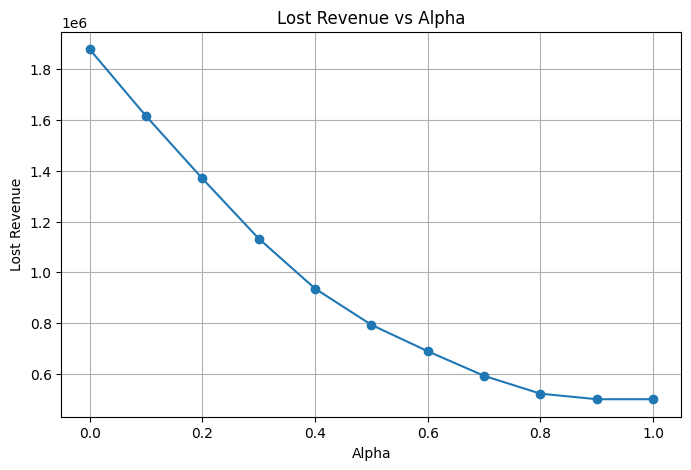

In [20]:
plt.figure(figsize=(8,5))
plt.plot(results_df["alpha"], results_df["lost_revenue"], marker="o")
plt.xlabel("Alpha")
plt.ylabel("Lost Revenue")
plt.title("Lost Revenue vs Alpha")
plt.grid(True)
plt.show()

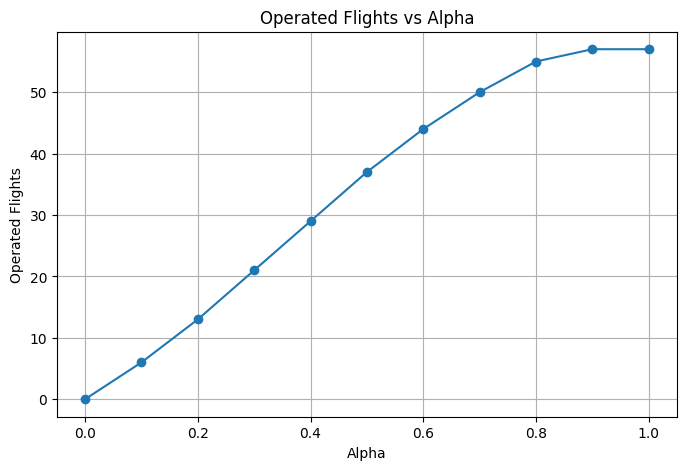

In [21]:
plt.figure(figsize=(8,5))
plt.plot(results_df["alpha"], results_df["operated_flights"], marker="o")
plt.xlabel("Alpha")
plt.ylabel("Operated Flights")
plt.title("Operated Flights vs Alpha")
plt.grid(True)
plt.show()

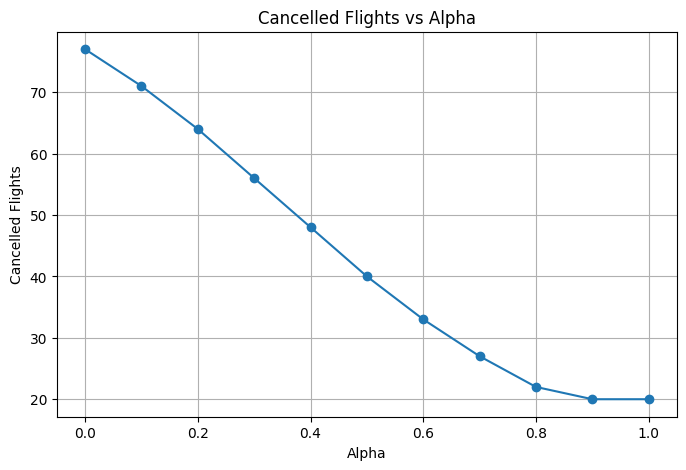

In [22]:
plt.figure(figsize=(8,5))
plt.plot(results_df["alpha"], results_df["cancelled_flights"], marker="o")
plt.xlabel("Alpha")
plt.ylabel("Cancelled Flights")
plt.title("Cancelled Flights vs Alpha")
plt.grid(True)
plt.show()

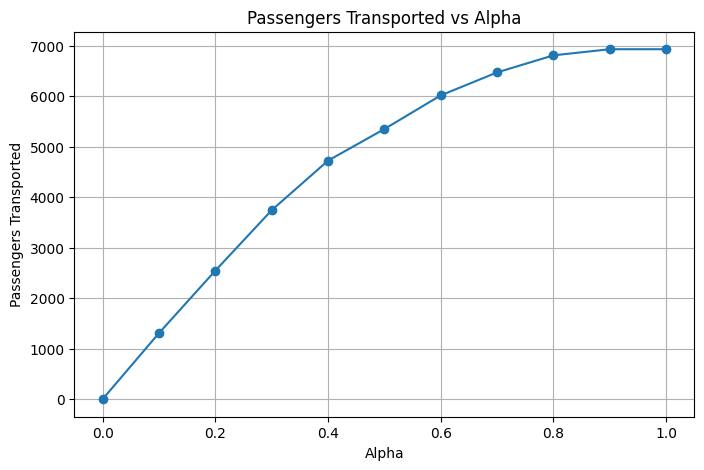

In [23]:
plt.figure(figsize=(8,5))
plt.plot(results_df["alpha"], results_df["passengers_transported"], marker="o")
plt.xlabel("Alpha")
plt.ylabel("Passengers Transported")
plt.title("Passengers Transported vs Alpha")
plt.grid(True)
plt.show()

In [24]:
results_df.to_csv("alpha_sensitivity_results.csv", index=False)
print("Saved alpha_sensitivity_results.csv")

Saved alpha_sensitivity_results.csv
